# EEC174AY Project A1: PreLab
You are NOT allowed to import any other libraries in this notebook otherwise points will be deducted. If you need to please confirm with the TA. ''' TODO ''' Indicates where your solution code should go. Please ensure code is readable easily.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Part 1: Visualizing Ground Truth Bounding Boxes

The code below is provided to load `imgs/cats.jpg` and display it using [opencv](https://docs.opencv.org/4.x/).

You must add code to display the bounding boxes, which are given as `gt_boxes` in green color. These represent the ground truth bounding box coordinates in `[x, y, w, h]` format.

Please use `cv2.rectange()` to achieve this. Click [here](https://docs.opencv.org/4.x/dc/da5/tutorial_py_drawing_functions.html) to see hint.

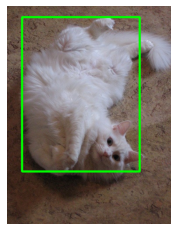

In [15]:
# Load the image
image_path = "imgs/cat.jpg"
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Ground truth bounding box [x, y, w, h]
gt_box = [34, 25, 303, 379] # x and y are the coordinates for top left of the box, w and h are bottom right

# Use gt_boxes and display the bounding boxes in green color
cv2.rectangle(image_rgb,(34,25),(303,379),(0,255,0),3)
#cv2.rectangle(image_rgb,(gt_box[0],gt_box[1]),(gt_box[2],gt_box[3]),(0,255,0),3)

# Display the image with bounding boxes using matplotlib
plt.imshow(image_rgb)
plt.axis('off')  # Hide axes
plt.show()


## Part 2: Implementing the IoU Function

Complete the `compute_iou()` function. This function should accept two bounding boxes and return the IoU value between them. Ensure that the function can handle edge cases (e.g., no overlap between the boxes).

(Hint: See Lecture W5L1_Object Detection Slide 11)

In [20]:
def compute_iou(boxA, boxB):
    #if the user draws the rectangle BL to TR instead of TL to BR for some reason
    if boxA[1] > boxA[3]: #starting corner is lower than ending corner
        temp = boxA[1]    #store start corner's height
        boxA[1] = boxA[3] #set start corner's height to end corner's height
        boxA[3] = temp    #set end corner's height to start corner's original height
    
    if boxB[1] > boxB[3]: #starting corner is lower than ending corner
        temp = boxB[1]    #store start corner's height
        boxB[1] = boxB[3] #set start corner's height to end corner's height
        boxB[3] = temp    #set end corner's height to start corner's original height
        
        #x values stay the same 
        #RANDALL WE KNOW THERE ARE OTHER CASES BUT THE CONCEPT IS THE SAME! THIS IF STATEMENT ONLY COVERS THE EXAMPLE IN PART 3
    
    widthA = boxA[2] - boxA[0]
    heightA = boxA[3] - boxA[1]
    areaA = widthA * heightA
    
    widthB = boxB[2] - boxB[0]
    heightB = boxB[3] - boxB[1]
    areaB = widthB * heightB
    
    
    x_int1 = max(boxA[0], boxB[0]) #x of top left 
    y_int1 = max(boxA[1], boxB[1]) #y of top left
    x_int2 = min(boxA[2], boxB[2]) #x of bottom right
    y_int2 = min(boxA[3], boxB[3]) #y of bottom right
    
        
    
    intersect_width = max(0, x_int2 - x_int1)
    intersect_height = max(0, y_int2 - y_int1)
    intersect_area = intersect_width * intersect_height
    
    union_area = areaA + areaB - intersect_area
    
    return intersect_area / union_area

## Part 3: Visualizing Predicted Bounding Boxes and Computing IoUs

Four sets of predicted bounding boxes have been provided in `predictions`. The ground truth bounding boxes are in `gt_boxes`

For each set of predicted bounding boxes:
1. Draw the predicted boxes on a copy of the original image in red.
2. Draw the ground truth boxes on the same image in green.
3. Compute the IoU for predictions and ground truth.
4. Display the image with both the predicted and ground truth boxes. Use the title of the plot to display the maximum IoU value for each prediction.

You should have 4 images, each with a GT and prediction (1,2,3 or 4) bounbding box plotted (GT in green,. pred in red), and the IoU be the title of the images.

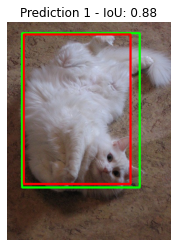

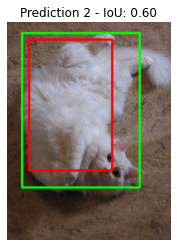

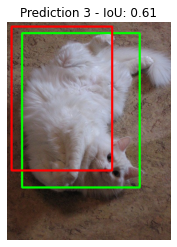

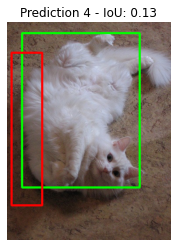

In [21]:
# Predicted bounding boxes [x, y, w, h]
predictions = [
    [38, 28, 282, 371],  # Pred 1
    [50, 40, 240, 340],  # Pred 2
    [10, 10, 240, 340],  # Pred 3
    [10, 420, 80, 70]    # Pred 4
]

# For each predicted box, visualize it on the image individually (with GT)
#   and compute its IoU with the ground truth.

for i, pred in enumerate(predictions):
    #display image
    img_display = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    #dimensions of ground truth, draw rectangle
    gx, gy, gw, gh = gt_box
    cv2.rectangle(img_display,(gx, gy),(gw, gh),(0,255,0),3)
    
    #dimensions of prediction, draw rectangle
    px, py, pw, ph = pred
    cv2.rectangle(img_display,(px, py),(pw, ph),(255,0,0),3)
    
    iou_value = compute_iou(gt_box, pred)
    
    plt.figure()
    plt.imshow(img_display)
    plt.title(f"Prediction {i+1} - IoU: {iou_value:.2f}")
    plt.axis("off")
    plt.show()
    
